# Étape 2 – Construction du corpus et couverture réelle des médias

**Projet : Emerging Topic Detection and Temporal Evolution in Local News Media – Lyon / GDELT**

Ce notebook documente (1) d'où viennent les données, (2) comment le corpus a été construit et (3) ce qu'il contient vraiment.
Tous les chiffres sont calculés sur `data/processed/corpus.parquet`, produit par `python -m src.preprocessing.build_corpus`.

## Source des données : pourquoi les fichiers GKG et pas l'API DOC 2.0
L'API DOC 2.0 (`mode=artlist`) a renvoyé des erreurs HTTP 429 puis des réponses vides (`{}`) lors de nos tests (le 2 novembre 2026),
y compris pour un média témoin (Le Monde) et depuis plusieurs réseaux. Nous n'avons donc **aucun résultat issu de l'API**.
Nous avons collecté à la place les fichiers bruts **GDELT GKG 2.0 « translation »** (`data.gdeltproject.org/gdeltv2/*.translation.gkg.csv.zip`),
publiés toutes les 15 minutes, qui indexent les articles des médias non anglophones. Le flux GKG anglophone standard n'en contient presque pas
(test du 1er novembre : 7 articles en `.fr` sur 54 361, aucun média lyonnais).
Chaque tranche est téléchargée, filtrée sur les domaines ciblés et seules les lignes utiles sont conservées (`src/data_collection/gkg_collector.py`).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
corpus = pd.read_parquet(ROOT / "data" / "processed" / "corpus.parquet")
raw_rows = sum(len(pd.read_csv(f)) for f in sorted((ROOT / "data" / "raw" / "gkg").glob("*.csv.gz")))
print(f"{raw_rows:,} lignes brutes → {len(corpus):,} articles après dédoublonnage par URL")
print(f"Période : {corpus['date'].min().date()} → {corpus['date'].max().date()} ({corpus['seendate'].dt.normalize().nunique()} jours de détection)")

13,999 lignes brutes → 13,998 articles après dédoublonnage par URL
Période : 2026-08-02 → 2026-11-01 (91 jours de détection)


## 1. Couverture par média (remplace le tableau de test de l'étape 1)
Les 7 médias de départ ont été testés ; **seuls 4 apparaissent dans GDELT** sur ces 91 jours. Rue89Lyon, Tribune de Lyon et Actu Lyon
n'ont aucun article, aucun des jours (le filtre cherche `rue89lyon.fr`, `tribunedelyon.fr`, `lyon.actu.fr`).

In [2]:
TARGETS = {"Le Progrès": "leprogres.fr", "Lyon Capitale": "lyoncapitale.fr", "Rue89Lyon": "rue89lyon.fr", "LyonMag": "lyonmag.com",
           "BFM Lyon": "bfmtv.com/lyon", "Tribune de Lyon": "tribunedelyon.fr", "Actu Lyon": "lyon.actu.fr"}
n_days = (corpus["seendate"].dt.normalize().max() - corpus["seendate"].dt.normalize().min()).days + 1
g = corpus.groupby("media_name")
cov = pd.DataFrame({
    "Domaine": pd.Series(TARGETS),
    "Articles": g.size(),
    "Part (%)": (100 * g.size() / len(corpus)).round(1),
    "Articles/jour": (g.size() / n_days).round(1),
    "Jours couverts": g["date"].nunique(),
    "Début": g["date"].min().dt.date, "Fin": g["date"].max().dt.date,
    "Titres présents (%)": g["title"].apply(lambda s: 100 * (s.str.len() > 0).mean()).round(1),
}).reindex(TARGETS).fillna({"Articles": 0, "Jours couverts": 0}).astype({"Articles": int, "Jours couverts": int})
def verdict(r):
    if r["Articles"] == 0: return "Non : absent de GDELT"
    if r["Articles"] < 200 or r["Jours couverts"] < 0.8 * n_days: return "Non : trop peu / irrégulier"
    return "Oui"
cov["Exploitable ?"] = cov.apply(verdict, axis=1)
cov.to_csv(ROOT / "outputs" / "tables" / "step2_coverage_all_media.csv")
cov

,Domaine,Articles,Part (%),Articles/jour,Jours couverts,Début,Fin,Titres présents (%),Exploitable ?
Le Progrès,leprogres.fr,11233,80.2,123.4,92,2026-08-02,2026-11-01,100.0,Oui
Lyon Capitale,lyoncapitale.fr,1855,13.3,20.4,91,2026-08-03,2026-11-01,100.0,Oui
Rue89Lyon,rue89lyon.fr,0,NaN,NaN,0,NaN,NaN,NaN,Non : absent de GDELT
LyonMag,lyonmag.com,832,5.9,9.1,91,2026-08-03,2026-11-01,100.0,Oui
BFM Lyon,bfmtv.com/lyon,78,0.6,0.9,52,2026-08-06,2026-10-31,100.0,Non : trop peu / irrégulier
Tribune de Lyon,tribunedelyon.fr,0,NaN,NaN,0,NaN,NaN,NaN,Non : absent de GDELT
Actu Lyon,lyon.actu.fr,0,NaN,NaN,0,NaN,NaN,NaN,Non : absent de GDELT


**Lecture.** Le corpus repose sur **Le Progrès (80 %)**, avec Lyon Capitale (13 %) et LyonMag (6 %) en complément. BFM Lyon (78 articles, présent 52 jours sur 91)
est trop faible pour être analysé ; le filtre ne retient que les URL `bfmtv.com/lyon…`, ce qui peut sous-estimer sa couverture.
La comparaison équilibrée entre les 7 médias initiaux **n'est pas possible** : c'est une limite de la source à documenter dans le rapport.

## 2. Dates : publication ou détection ?
GDELT fournit la date de **détection** (`seendate`), pas celle de publication. Pour Le Progrès, l'URL contient la date de publication (`/2026/11/01/`).
Règle retenue : on utilise la date de l'URL si elle est à **2 jours ou moins** de la détection, sinon on garde la date de détection.
Les pages d'agenda (« pour-sortir ») portent la date de l'événement, parfois dans plusieurs semaines : elles seraient sinon placées dans le futur.

In [3]:
print(pd.crosstab(corpus["media_name"], corpus["date_source"], margins=True))
lp = corpus[corpus["media_name"] == "Le Progrès"].copy()
lp["gap_days"] = (lp["seendate"].dt.normalize() - lp["date"]).dt.days
print("\nÉcart détection − date retenue (Le Progrès, jours) :")
print(lp["gap_days"].value_counts().sort_index().to_string())

date_source    gdelt_seendate    url    All
media_name                                 
BFM Lyon                   78      0     78
Le Progrès                304  10929  11233
Lyon Capitale            1855      0   1855
LyonMag                   832      0    832
All                      3069  10929  13998

Écart détection − date retenue (Le Progrès, jours) :
gap_days
-2        6
-1      120
 0    10621
 1      465
 2       21


Pour **LyonMag, Lyon Capitale et BFM Lyon**, l'URL n'a pas de date : la date retenue est celle de détection. Elle suit en pratique la publication de très près
(le flux GKG est mis à jour toutes les 15 minutes), mais un article ancien republié ou détecté tardivement sera daté de sa détection. Pour des tendances hebdomadaires, ce biais est faible.

## 3. Périmètre : articles de la zone lyonnaise
Le Progrès est un quotidien **régional** (Ain, Jura, Loire, Haute-Loire, Rhône…). Environ 97 % de ses titres commencent par un lieu (« Lagnieu. … »).
Règles du filtre (`src/preprocessing/lyon_filter.py`) : préfixe de lieu appartenant au Rhône ou à la métropole ; sinon mot lyonnais dans le titre
(Lyon, Villeurbanne, Rhône en excluant « Bouches-du-Rhône », « Sérézin-du-Rhône »…, communes de la métropole, sigles) ; sinon géolocalisation GDELT sur Lyon ou Villeurbanne.
**Périmètre d'analyse (`in_scope`)** = tous les articles des médias basés à Lyon (Lyon Capitale, LyonMag, BFM Lyon) + les articles de Le Progrès retenus par le filtre.

In [4]:
print(corpus.groupby(["media_name", "lyon_rule"], dropna=False).size().unstack(fill_value=0).rename(columns={np.nan: "non retenu"}))
scope = corpus[corpus["in_scope"]]
print(f"\nPérimètre d'analyse : {len(scope):,} articles sur {len(corpus):,} ({len(scope) / len(corpus):.0%})")
print(scope["media_name"].value_counts().to_string())

lyon_rule      gkg_loc  prefix  title  non retenu
media_name                                       
BFM Lyon             0       0     72           6
Le Progrès           3    1935    323        8972
Lyon Capitale        9       0   1202         644
LyonMag              4       0    707         121

Périmètre d'analyse : 5,026 articles sur 13,998 (36%)
media_name
Le Progrès       2261
Lyon Capitale    1855
LyonMag           832
BFM Lyon           78


In [5]:
# Contrôle qualité du filtre : lecture d'échantillons (aucune « vérité terrain » n'existe, c'est une inspection manuelle)
sample_cols = ["place_prefix", "title"]
print("— Le Progrès RETENUS par le titre :"); display(corpus[(corpus.media_name == "Le Progrès") & (corpus.lyon_rule == "title")].sample(8, random_state=1)[sample_cols])
print("— Le Progrès EXCLUS :"); display(corpus[(corpus.media_name == "Le Progrès") & ~corpus.is_lyon].sample(8, random_state=1)[sample_cols])

— Le Progrès RETENUS par le titre :


,place_prefix,title
8512,Oullins-Pierre-Bénite | Mariage,Oullins-Pierre-Bénite | Mariage. Félicitations à Yasmine et Jérémy
6156,Cinéma,"Cinéma. De Jean Moulin à Lucie Aubrac, Lyon met en scène ses figures historiques sur le grand écran"
12728,Lyon 5e Arrondissement,"Lyon 5e Arrondissement. Les conséquences du réchauffement climatique, une pièce de la Compagnie Les Lueurs"
10764,Spectacle de Bruta Corp,Spectacle de Bruta Corp. : Spectacle de danse a Villeurbanne
4649,Météo,"Météo. Un pic de chaleur attendu jusqu'à lundi à Lyon, jusqu'à 10 degrés au-dessus des normales de saison"
11764,En images,"En images. En marge de la manifestation du 17 octobre, une Marche du refus de la misère à Villeurbanne"
9449,Fleurie,Fleurie. Comment ce marché aux vins du Beaujolais a réussi à durer 100 ans
11456,NaN,"Concert du groupe artistique ""C est extra"" : Concert Chanson variete a Villeurbanne"


— Le Progrès EXCLUS :


,place_prefix,title
10144,Jura,Jura. Cette dentiste est une ancienne sprinteuse olympique espagnole
452,Guatemala,Guatemala. Fin de l'éruption du volcan de Fuego après l'évacuation de 1 700 personnes
13241,Automobile,Automobile. Assurance : jusqu'à 40 % d'économies possibles… mais à quel prix ?
295,Saint-Étienne,"Saint-Étienne. Les 6 Roses, un bar emblématique « à la lisière du centre-ville »"
5770,Doubs,Doubs. « Le garde forestier en avait plein son coffre » : plus de 60 kg de courrier jetés en forêt par un ...
2589,Saint-Quentin-Fallavier,Saint-Quentin-Fallavier. Une dernière marche pour clôturer les balades du mois d'août
7244,Ain,"Ain. Bourg-en-Bresse : de la maternité à la maison de retraite, la belle histoire de la résidence Pélicand"
13641,Dans nos départements,"Dans nos départements. Chevaux, vins, Gaulois... Nos 10 idées de sorties pour le week-end du 31 octobre et..."


**Évaluation du filtre (lecture d'environ 60 titres lors de la mise au point).**
- *Le Progrès, exclus* : correctement hors zone dans l'immense majorité (Saint-Étienne, Roanne, Ain, Jura, national, international).
- *Le Progrès, retenus* : quelques faux positifs subsistent (exemple : un article « Énergie. … » retenu par la géolocalisation GDELT).
- *Lyon Capitale / LyonMag* : le filtre manquerait des articles lyonnais sans mot-clé (« un féminicide aux Célestins »), d'où le choix de garder ces médias en entier.
Le filtre est donc une **heuristique à précision correcte et rappel limité** ; on la présentera comme telle. Une évaluation chiffrée supposerait d'annoter un échantillon à la main.

## 4. Volume dans le temps et par média

Articles/jour (tous médias) : {'count': 92, 'mean': 152, 'std': 31, 'min': 1, '25%': 143, '50%': 154, '75%': 171, 'max': 214}
Jours les plus creux :
2026-08-02      1
2026-10-12     47
2026-10-13     62
2026-10-11     96
2026-08-16    106


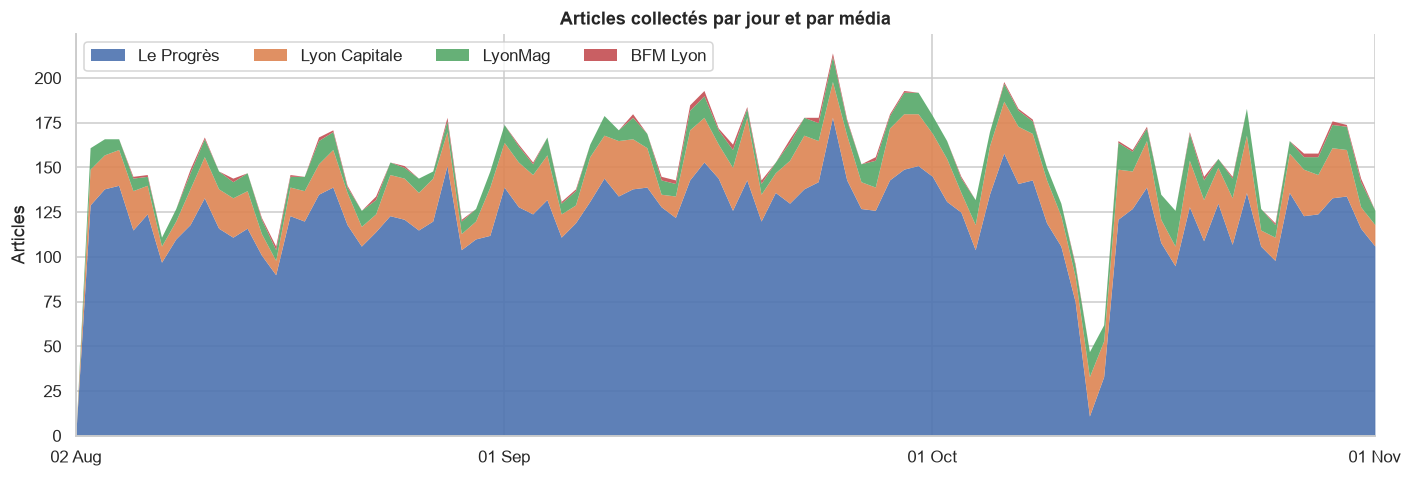

In [6]:
daily = corpus.groupby(["date", "media_name"]).size().unstack(fill_value=0)
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
print("Articles/jour (tous médias) :", daily.sum(axis=1).describe().round(0).astype(int).to_dict())
print("Jours les plus creux :"); print(daily.sum(axis=1).nsmallest(5).to_string())

fig, ax = plt.subplots(figsize=(13, 4.5))
daily[["Le Progrès", "Lyon Capitale", "LyonMag", "BFM Lyon"]].plot.area(ax=ax, linewidth=0, alpha=0.9)
ax.set(title="Articles collectés par jour et par média", ylabel="Articles", xlabel="")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(title="", loc="upper left", ncol=4)
plt.tight_layout(); fig.savefig(FIG / "02_volume_par_jour.png", bbox_inches="tight"); plt.show()

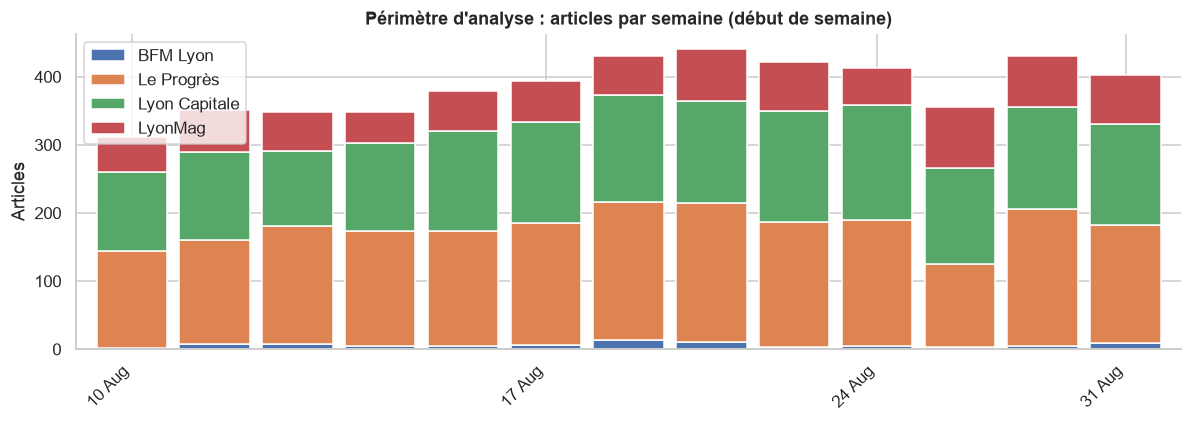

13 semaines complètes, du lundi 3 août au dimanche 1er novembre (le 2 août, un seul article, est hors tableau).


media_name,BFM Lyon,Le Progrès,Lyon Capitale,LyonMag,total
week_start,,,,,
2026-08-03,2,142,116,51,311
2026-08-10,8,153,128,62,351
2026-08-17,7,174,110,57,348
2026-08-24,4,170,129,45,348
2026-08-31,4,170,147,58,379
2026-09-07,6,179,149,59,393
2026-09-14,13,203,157,58,431
2026-09-21,10,204,150,77,441
2026-09-28,3,184,162,73,422


In [7]:
weekly = scope.groupby(["week_start", "media_name"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
weekly.plot.bar(stacked=True, ax=ax, width=0.85)
ax.set(title="Périmètre d'analyse : articles par semaine (début de semaine)", ylabel="Articles", xlabel="")
ax.set_xticklabels([d.strftime("%d %b") for d in weekly.index], rotation=45, ha="right"); ax.legend(title="")
plt.tight_layout(); fig.savefig(FIG / "02_volume_par_semaine_perimetre.png", bbox_inches="tight"); plt.show()
print("13 semaines complètes, du lundi 3 août au dimanche 1er novembre (le 2 août, un seul article, est hors tableau).")
weekly.assign(total=weekly.sum(axis=1))

### Trou de couverture à surveiller
Le volume hebdomadaire de Le Progrès chute la semaine du 12 octobre. Ce n'est pas un trou de **notre** collecte : le nombre de lignes GKG parcourues ces jours-là était normal
(≈ 207 000 le 12 et ≈ 227 000 le 13 octobre) ; c'est **GDELT qui n'a pas indexé Le Progrès** (aucune détection de Le Progrès le 13 octobre ; quelques articles datés du 12-13 n'apparaissent que le 14 ; retour à la normale ensuite, sans rattrapage du reste).
Un sujet ne doit pas passer pour « en déclin » à cause de ce trou : on repère donc automatiquement les jours anormalement creux de chaque média.
Les creux de Lyon Capitale signalés ci-dessous tombent surtout un samedi ou un dimanche (effet de week-end normal) : seuls **le 2 août (début de période) et les 12-13 octobre (Le Progrès)** sont de vraies anomalies.

In [8]:
# Jour « creux » : moins de 50 % de la médiane glissante centrée (15 jours) du même média
daily_media = daily[["Le Progrès", "Lyon Capitale", "LyonMag"]]
baseline = daily_media.rolling(15, center=True, min_periods=7).median()
low = (daily_media < 0.5 * baseline)
gaps = pd.DataFrame([(d, m, int(daily_media.loc[d, m]), int(baseline.loc[d, m]))
                     for m in daily_media for d in daily_media.index[low[m]]],
                    columns=["date", "média", "articles", "médiane locale"]).set_index("date").sort_index()
display(gaps)
LOW_DAYS = sorted(set(gaps.index))
print("Jours à exclure ou à pondérer pour la détection d'émergence :", [d.strftime("%Y-%m-%d") for d in LOW_DAYS])

,média,articles,médiane locale
date,,,
2026-08-02,Le Progrès,1,119
2026-08-02,Lyon Capitale,0,17
2026-08-02,LyonMag,0,6
2026-08-08,Lyon Capitale,9,20
2026-08-16,Lyon Capitale,8,17
2026-08-21,LyonMag,3,8
2026-08-29,Lyon Capitale,9,22
2026-08-30,Lyon Capitale,10,22
2026-09-06,Lyon Capitale,10,24


Jours à exclure ou à pondérer pour la détection d'émergence : ['2026-08-02', '2026-08-08', '2026-08-16', '2026-08-21', '2026-08-29', '2026-08-30', '2026-09-06', '2026-09-12', '2026-09-20', '2026-10-03', '2026-10-12', '2026-10-13', '2026-10-21', '2026-10-24']


## 5. Qualité : valeurs manquantes, doublons, rubriques

In [9]:
miss = corpus.isna().sum().to_frame("manquants"); miss["%"] = (100 * miss["manquants"] / len(corpus)).round(1)
print("Colonnes avec valeurs manquantes :"); display(miss[miss["manquants"] > 0])
print(f"Titres vides : {(corpus['title'].str.len() == 0).sum()} | URL vides : {(corpus['url'].str.len() == 0).sum()} | dates manquantes : {corpus['date'].isna().sum()}")
print(f"Doublons d'URL après normalisation : {corpus['url'].str.lower().duplicated().sum()} | articles dont le titre est partagé par un autre article du même média : {corpus['dup_title'].sum()}")
display(corpus[corpus.dup_title].groupby(["media_name", "title"]).size().sort_values(ascending=False).head(8).to_frame("occurrences"))

Colonnes avec valeurs manquantes :


,manquants,%
section,896,6.4
place_prefix,3056,21.8
lyon_rule,9743,69.6
socialimage,167,1.2
themes,561,4.0
persons,11075,79.1
organizations,9394,67.1
locations,5625,40.2


Titres vides : 0 | URL vides : 0 | dates manquantes : 0
Doublons d'URL après normalisation : 0 | articles dont le titre est partagé par un autre article du même média : 60


occurrences
media_name    title                                                                                                                      
Lyon Capitale Le récap' des temps forts de la semaine                                                                                   7
Le Progrès    Conference UPT : Conference a Yssingeaux                                                                                  5
              Animation du Syndicat des cinemas d art, de repertoire et d essai : Cinema   Projection a Villeurbanne                    3
LyonMag       Pas de cours à l'université Lyon 2 ce lundi à cause des blocus, 27 établissements touchés dans le Rhône                   3
              Mobilisation à Lyon : la façade d'un lycée incendiée, tirs de mortiers, collégien blessé… la matinée démarr...            3
Le Progrès    The dansant : The dansant a Yssingeaux                                                                                    3
Lyon Capitale Feux de forêts : sept départements d'Auvergne-Rhône-Alpes en vigilance                                                    2
LyonMag       Mort de Quentin Deranque à Lyon : cinq nouvelles mises en examen, 14 suspects désormais poursuivis                        2

- **`persons` (79 % manquants) et `organizations` (67 %)** : les entités GDELT sont souvent absentes ; elles ne serviront que de signal complémentaire.
- **Titres en double** : ils sont signalés (`dup_title`), pas supprimés. Beaucoup sont des **fiches d'agenda** répétées (« Conference … à Yssingeaux ») ou des rubriques récurrentes (« Le récap' des temps forts de la semaine ») ; on y reviendra avant le clustering.
- **Pas de texte intégral** : seul le titre est disponible. `sourcecountry` n'existe pas dans le GKG ; tous les articles sont en français (`language` = `fra`).

In [10]:
sec = corpus[corpus.in_scope].groupby(["media_name", "section"]).size().sort_values(ascending=False)
print("Rubriques (URL) dans le périmètre :"); display(sec.groupby(level=0).head(6).to_frame("articles"))

Rubriques (URL) dans le périmètre :


articles
media_name    section                       
Lyon Capitale actualite                 1657
Le Progrès    faits-divers-justice       537
              economie                   527
              societe                    239
              culture-loisirs            171
              education                  149
              politique                  138
Lyon Capitale culture                     87
              regions                     50
BFM Lyon      faits-divers                16
Lyon Capitale logement-immobilier         10
              a-table                      7
              politique                    6
BFM Lyon      info-trafic                  1

## 6. Synthèse (étape 2)

- **Source** : API DOC 2.0 inutilisable (429 / réponses vides) → collecte via les fichiers GDELT GKG « translation », 91 jours (3 août – 1er novembre 2026), aucune tranche de 15 min manquante.
- **Corpus** : 13 998 articles uniques (1 doublon d'URL), **5 026 dans le périmètre** lyonnais ; ~55 articles/jour, 311 à 441 par semaine.
- **Médias** : Le Progrès (80 %), Lyon Capitale (13 %), LyonMag (6 %) exploitables ; BFM Lyon trop faible ; Rue89Lyon, Tribune de Lyon, Actu Lyon absents de GDELT.
- **Trou GDELT** : Le Progrès quasi absent du 11 au 13 octobre (75, 11 puis 33 articles datés de ces jours, contre ≈ 120-140 en temps normal) ; à neutraliser pour la détection d'émergence.
- **Limites à écrire dans le rapport** : titres seulement ; corpus dominé par un média régional (biais éditorial de Le Progrès) ; filtre lyonnais heuristique ; date de détection ≠ date de publication (corrigée via l'URL pour Le Progrès seulement) ; GDELT n'indexe qu'une partie des articles.
- **Suite** : EDA détaillée (étape 3) puis analyse textuelle des titres. À prévoir : traiter les fiches d'agenda répétitives et normaliser les fréquences par le volume hebdomadaire.